In [1]:
import numpy as np
import matplotlib.pyplot as plt

# import distribution.distribution_functions.random_mps as rmps

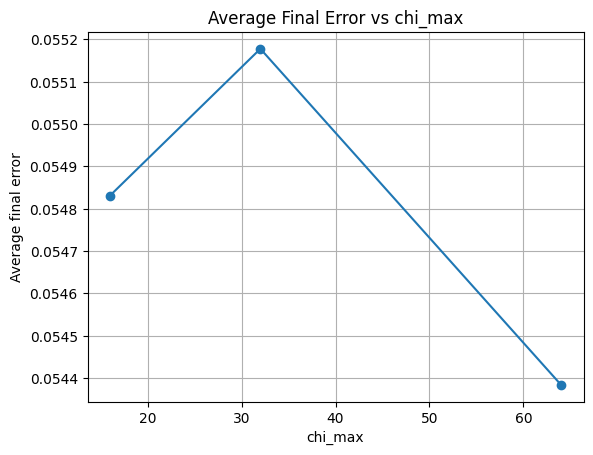

In [3]:
L = int(12)
chi_values = [16, 32, 64]#, 128, 256, 512]

avg_errors = []

for chi in chi_values:
    filename = f"new_list_of_list_errors_L{L}_standard_deviationNone_chi_max{chi}.npy"
    
    # Load the list of error lists
    data = np.load(filename, allow_pickle=True)
    
    # Each entry is a list/array of errors → take the last error
    last_errors = [errors[-1] for errors in data]
    
    # Compute the average
    avg_errors.append(np.mean(last_errors))

# Plot
plt.plot(chi_values, avg_errors, marker='o')
plt.xlabel("chi_max")
plt.ylabel("Average final error")
plt.title("Average Final Error vs chi_max")
plt.grid(True)
plt.show()


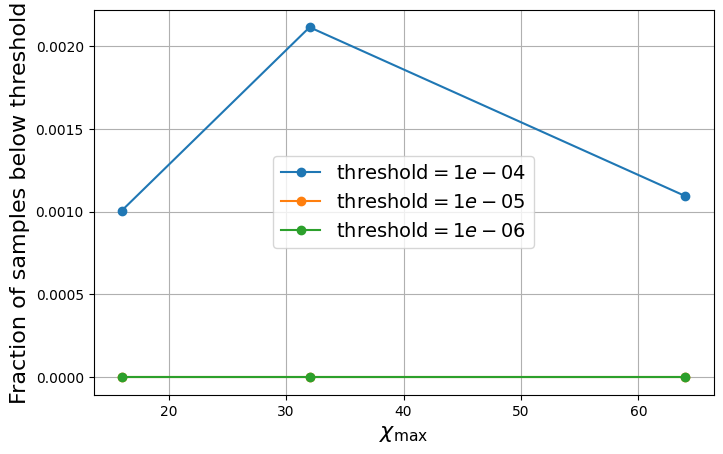

In [4]:
thresholds = [1e-4, 1e-5, 1e-6]

plt.figure(figsize=(8, 5))

for threshold in thresholds:
    rates = []

    for chi in chi_values:
        filename = f"new_list_last_errors_L{L}_standard_deviationNone_chi_max{chi}.npy"
        
        # Load last errors
        list_last_errors = np.load(filename, allow_pickle=True)

        # Percentage under threshold
        count_ok = sum(err < threshold for err in list_last_errors)
        rate = count_ok / len(list_last_errors)
        rates.append(rate)

    plt.plot(
        chi_values,
        rates,
        marker='o',
        label=rf"$\mathrm{{threshold}} = {threshold:.0e}$"
    )

plt.xlabel(r"$\chi_{\max}$", fontsize=16)
plt.ylabel("Fraction of samples below threshold", fontsize=16)
# plt.title("Convergence rate vs $\chi_{\max}$", fontsize=18)

plt.grid(True)
plt.legend(fontsize=14)
plt.show()
# plt.savefig("fraction_sample_below_threshold.pdf", bbox_inches="tight")


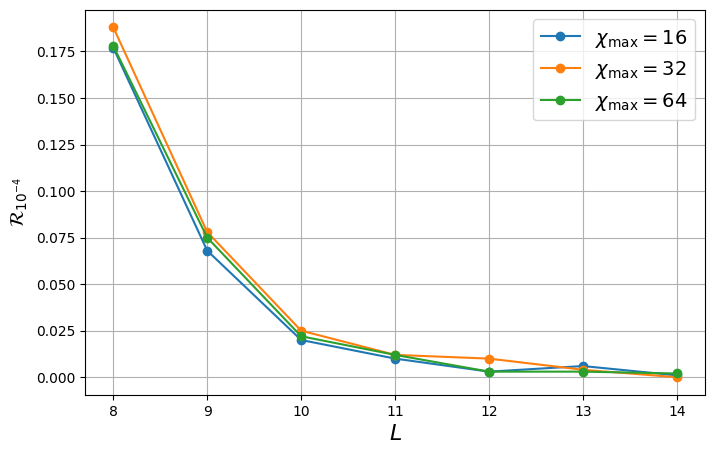

In [4]:
threshold = 1e-4          # choose ONE threshold
chi_values = [16, 32, 64] # the 3 chi_max you want to compare
L_values = [8, 9, 10, 11, 12, 13, 14]  # example L values

plt.figure(figsize=(8, 5))

for chi in chi_values:
    rates = []

    for L in L_values:
        
        filename = f"new_list_last_errors_L{L}_standard_deviationNone_chi_max{chi}_number_tests10000.npy"
        
        # Load last errors
        list_last_errors = np.load(filename, allow_pickle=True)
        list_last_errors = list_last_errors

        # Fraction under threshold
        count_ok = sum(err < threshold for err in list_last_errors)
        rate = count_ok / 1000 #len(list_last_errors)
        rates.append(rate)


    plt.plot(
        L_values,
        rates,
        marker='o',
        label=rf"$\chi_{{\max}} = {chi}$"
    )

plt.xlabel(r"$L$", fontsize=16)
plt.ylabel(r"$\mathcal{R}_{10^{-4}}$", fontsize=14)
# Log scale on y-axis
# plt.yscale("log")
from matplotlib.ticker import MaxNLocator
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))




plt.grid(True)#, which="both")
plt.legend(fontsize=14)
plt.savefig("fraction_vs_L_for_different_chi.pdf", bbox_inches="tight")
plt.show()



In [ ]:
print(len(list_last_errors))

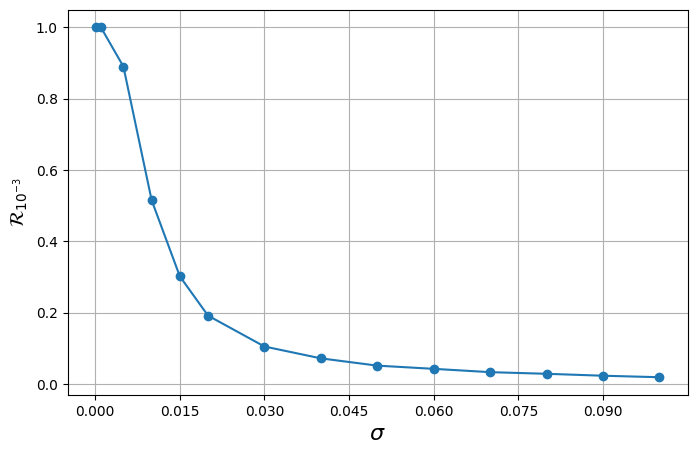

In [2]:
threshold = 1e-3         # choose ONE threshold
# sigma_values = [0.0001, 0.001, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1] 
sigma_values = [0.0001, 0.001, 0.005, 0.01, 0.015, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]
L = 12  
chi_max = 64
rates = []
plt.figure(figsize=(8, 5))
n_tests =10000


for sigma in sigma_values:
    filename = f"new_list_last_errors_L{L}_standard_deviation{sigma}_chi_max{chi_max}_number_tests{n_tests}.npy"
    
    # Load last errors
    list_last_errors = np.load(filename, allow_pickle=True)
    list_last_errors = list_last_errors

    # Fraction under threshold
    count_ok = sum(err < threshold for err in list_last_errors)
    rate = count_ok / n_tests #len(list_last_errors)
    rates.append(rate)

plt.plot(sigma_values, rates, marker='o')
plt.xlabel(r"$\sigma$", fontsize=16)
plt.ylabel(r"$\mathcal{R}_{10^{-3}}$", fontsize=14)

from matplotlib.ticker import MaxNLocator

plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

plt.grid(True)
# plt.legend(fontsize=14)
plt.savefig("fraction_vs_sigma.pdf", bbox_inches="tight")
plt.show()
np.savetxt(
    f"fraction_vs_sigma.txt",
    np.column_stack((sigma_values, rates))
)


In [4]:
print(rates)

[np.float64(0.8897), np.float64(0.5152), np.float64(0.3015), np.float64(0.1913), np.float64(0.1047), np.float64(0.0715), np.float64(0.0511), np.float64(0.0421), np.float64(0.0328), np.float64(0.0282), np.float64(0.0228), np.float64(0.0186)]
